Data exploration 

# Historical exploratory analysis only. The current scoring system is defined in train_high_risk_classifier.ipynb and uses its own point-in-time labels/features.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

project_root = next(
    (candidate for candidate in [Path.cwd(), *Path.cwd().parents]
     if (candidate / 'data' / 'raw').is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError('Could not find project root containing data/raw.')
base = project_root / 'data' / 'raw' / 'drive-download-20261006T150120Z-1-001'
analysis_date = pd.Timestamp('2018-08-31')

orders = pd.read_csv(base / 'orders.csv', parse_dates=[
    'order_purchase_timestamp', 'order_approved_at',
    'order_delivered_carrier_date', 'order_delivered_customer_date',
    'order_estimated_delivery_date'
])
order_lines = pd.read_csv(base / 'order_lines.csv', parse_dates=[
    'order_date', 'delivered_date', 'estimated_delivery_date'
])
order_lines['order_month'] = pd.to_datetime(order_lines['order_month'].astype(str) + '-01')

account_summary = order_lines.groupby('account_id').agg(
    first_order=('order_date', 'min'),
    last_order=('order_date', 'max'),
    order_count=('order_id', 'nunique'),
    total_revenue=('price', 'sum'),
    categories=('product_category', 'nunique'),
).reset_index()
account_summary['days_since_last_order'] = (analysis_date - account_summary['last_order']).dt.days

account_month = order_lines.groupby(['account_id', 'order_month']).agg(
    order_count=('order_id', 'nunique'), revenue=('price', 'sum')
).reset_index()
recent = account_month.loc[account_month['order_month'] >= pd.Timestamp('2018-06-01')]
prior = account_month.loc[
    (account_month['order_month'] >= pd.Timestamp('2018-03-01'))
    & (account_month['order_month'] < pd.Timestamp('2018-06-01'))
]
recent_summary = recent.groupby('account_id').agg(
    recent_order_count=('order_count', 'sum'), recent_revenue=('revenue', 'sum')
)
prior_summary = prior.groupby('account_id').agg(
    prior_order_count=('order_count', 'sum'), prior_revenue=('revenue', 'sum')
)
account_summary = account_summary.set_index('account_id').join(recent_summary).join(prior_summary).fillna({
    'recent_order_count': 0, 'recent_revenue': 0,
    'prior_order_count': 0, 'prior_revenue': 0,
}).reset_index()
account_summary['order_ratio_recent_to_prior'] = (
    account_summary['recent_order_count'] / account_summary['prior_order_count'].replace(0, np.nan)
)
account_summary['revenue_ratio_recent_to_prior'] = (
    account_summary['recent_revenue'] / account_summary['prior_revenue'].replace(0, np.nan)
)
account_summary['risk_score'] = (
    0.45 * account_summary['days_since_last_order'].gt(90)
    + 0.35 * account_summary['order_ratio_recent_to_prior'].fillna(1).le(0.5)
    + 0.20 * account_summary['revenue_ratio_recent_to_prior'].fillna(1).le(0.5)
)

/var/folders/tr/yrjk7jzx7qs3wg5y7fd4_smw0000gn/T/ipykernel_39569/1775678234.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_order, x='orders', y='product_category', palette='viridis', ax=axes[0])


Median orders per account: 4.0
Accounts with >90 days since last order: 7362
Accounts with very low recent order ratio (<=0.5): 4604
Top risk accounts:
account_id  order_count  days_since_last_order  risk_score
    A01003            1                    113         1.0
    A63590            1                    133         1.0
    A63530            3                    157         1.0
    A09689            4                    164         1.0
    A63540            2                    109         1.0
    A63560            7                    146         1.0
    A09685            2                    156         1.0
    A63580            1                    178         1.0
    A09668           10                     95         1.0
    A63030            4                    128         1.0


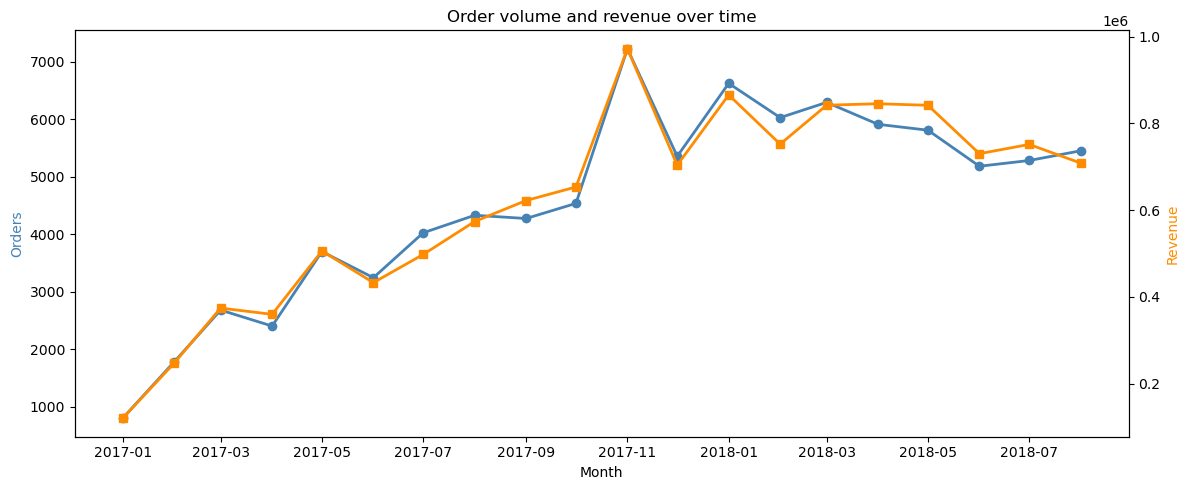

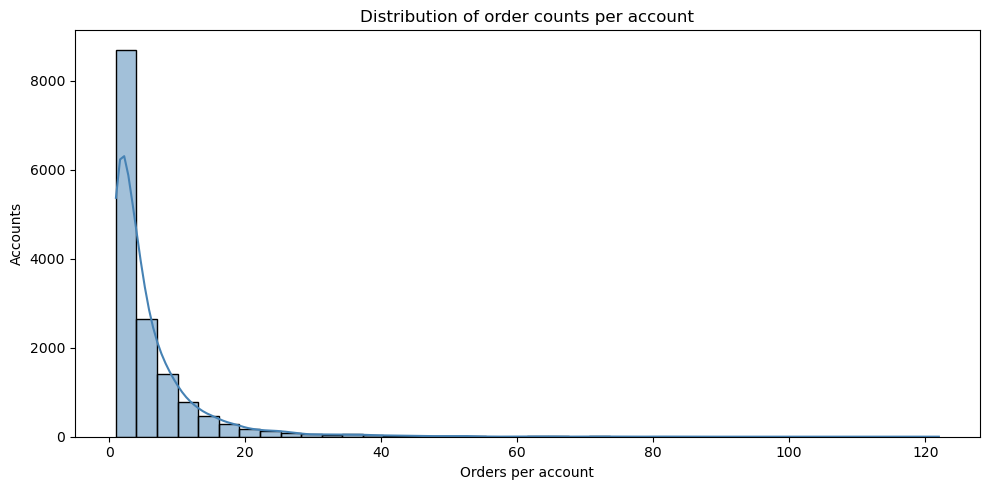

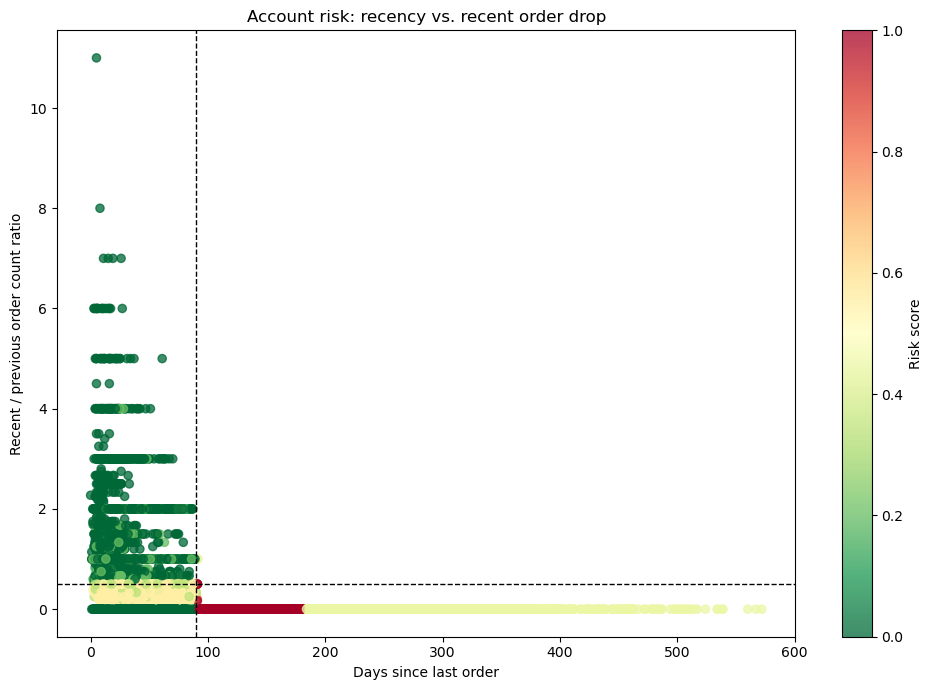

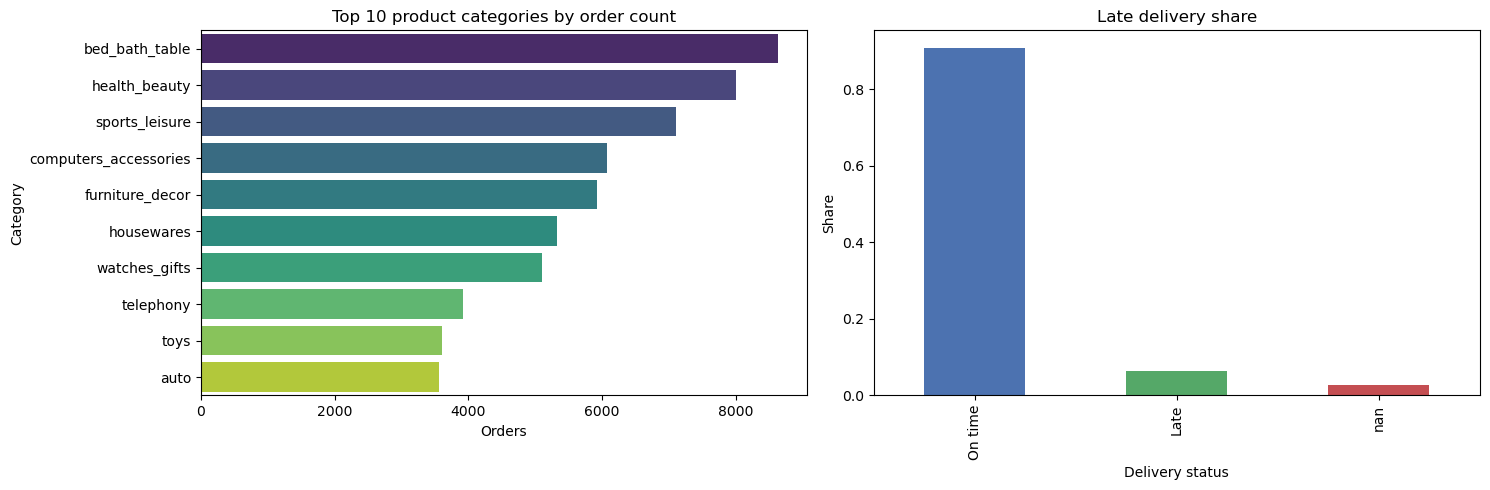

In [2]:
# Plot 1: monthly order volume
monthly_orders = (
    order_lines.groupby('order_month')
    .agg(orders=('order_id', 'nunique'), revenue=('price', 'sum'))
    .reset_index()
)

plt.figure(figsize=(12, 5))
ax1 = plt.gca()
ax2 = ax1.twinx()
ax1.plot(monthly_orders['order_month'], monthly_orders['orders'], color='steelblue', marker='o', linewidth=2)
ax2.plot(monthly_orders['order_month'], monthly_orders['revenue'], color='darkorange', marker='s', linewidth=2)
ax1.set_title('Order volume and revenue over time')
ax1.set_xlabel('Month')
ax1.set_ylabel('Orders', color='steelblue')
ax2.set_ylabel('Revenue', color='darkorange')
plt.tight_layout()

# Plot 2: distribution of order counts per account
plt.figure(figsize=(10, 5))
sns.histplot(account_summary['order_count'], bins=40, kde=True, color='steelblue')
plt.title('Distribution of order counts per account')
plt.xlabel('Orders per account')
plt.ylabel('Accounts')
plt.tight_layout()

# Plot 3: recency vs recent order drop
plot_df = account_summary[account_summary['order_count'] >= 2].copy()
plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    plot_df['days_since_last_order'],
    plot_df['order_ratio_recent_to_prior'].fillna(0),
    c=plot_df['risk_score'],
    cmap='RdYlGn_r',
    s=35,
    alpha=0.75,
)
plt.axhline(0.5, color='black', linestyle='--', linewidth=1)
plt.axvline(90, color='black', linestyle='--', linewidth=1)
plt.title('Account risk: recency vs. recent order drop')
plt.xlabel('Days since last order')
plt.ylabel('Recent / previous order count ratio')
plt.colorbar(scatter, label='Risk score')
plt.tight_layout()

# Plot 4: top categories and delivery lateness
reviews = pd.read_csv(base / 'order_reviews.csv')
late_share = order_lines['is_late'].value_counts(normalize=True, dropna=False)
late_share = late_share.rename(index={True: 'Late', False: 'On time', float('nan'): 'Not delivered'})
category_order = (
    order_lines.groupby('product_category')
    .agg(orders=('order_id', 'nunique'))
    .sort_values('orders', ascending=False)
    .head(10)
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=category_order, x='orders', y='product_category', palette='viridis', ax=axes[0])
axes[0].set_title('Top 10 product categories by order count')
axes[0].set_xlabel('Orders')
axes[0].set_ylabel('Category')

late_share.plot(kind='bar', ax=axes[1], color=['#4C72B0', '#55A868', '#C44E52'])
axes[1].set_title('Late delivery share')
axes[1].set_xlabel('Delivery status')
axes[1].set_ylabel('Share')
plt.tight_layout()

print('Median orders per account:', account_summary['order_count'].median())
print('Accounts with >90 days since last order:', (account_summary['days_since_last_order'] > 90).sum())
print('Accounts with very low recent order ratio (<=0.5):', (account_summary['order_ratio_recent_to_prior'].fillna(1) <= 0.5).sum())
print('Top risk accounts:')
print(account_summary[['account_id', 'order_count', 'days_since_last_order', 'risk_score']].sort_values('risk_score', ascending=False).head(10).to_string(index=False))
